# Case Study 3: Social Media Monitoring for Brand Management

## Objective

I build an end-to-end sentiment-monitoring workflow using the Twitter US Airline Sentiment dataset. I remove social-media noise, normalize and tokenize tweet text, train and tune a three-class sentiment classifier, evaluate it on unseen data, and create brand-level and time-based reports.

**Dataset:** 14,640 tweets about six US airlines, collected in February 2015. The dataset is historical, so it demonstrates the workflow rather than current airline reputation.
My workflow
1. Load and inspect the real dataset.
2. Explore the labeled sentiment distribution by class, airline, and date.
3. Remove URLs, hashtags, mentions, emoticons, and emoji symbols; normalize and tokenize the text.
4. Split the data into training and test sets before model selection.
5. Tune text features and SVM settings using cross-validation on training data only.
6. Evaluate the chosen configuration once on the held-out test set.
7. Use the model to score new posts and summarize sentiment by brand and date.

## 1. Imports

I keep the imports together so the notebook has one clear setup section. I also avoid reusing names such as display for variables, because that shadows Jupyter's table-display function.

In [230]:
from pathlib import Path
import html
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from IPython.display import display as show_table

RANDOM_STATE = 42
SENTIMENT_ORDER = ["negative", "neutral", "positive"]

# I download only the NLTK resources used by this notebook.
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")
print("Setup complete.")

Setup complete.


## Step 1 - Load & Inspect Data

In [231]:
DATASET_CANDIDATES = [
    Path("/kaggle/input/twitter-airline-sentiment/Tweets.csv"),
    Path("../input/twitter-airline-sentiment/Tweets.csv"),
    Path("Tweets.csv"),
    Path("../../../../Datasets/Twitter US Airline dataset/Tweets.csv"),
    Path("../Datasets/Twitter US Airline dataset/Tweets.csv"),
    Path.home() / "Datasets" / "Twitter US Airline dataset" / "Tweets.csv",
]

DATASET_PATH = next(
    (path for path in DATASET_CANDIDATES if path.is_file()),
    None,
)

if DATASET_PATH is None:
    checked_paths = "\n".join(f"  - {path}" for path in DATASET_CANDIDATES)
    raise FileNotFoundError(
        "I couldn't find Tweets.csv. Place it beside this notebook or add its "
        f"path to DATASET_CANDIDATES. Paths checked:\n{checked_paths}"
    )

df = pd.read_csv(DATASET_PATH, encoding="ISO-8859-1")

print(f"Loaded: {DATASET_PATH}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
print("\nColumns:")
print(df.columns.tolist())

show_table(df[["text", "airline", "airline_sentiment", "tweet_created"]].head())

Loaded: ../../../../Datasets/Twitter US Airline dataset/Tweets.csv
Rows: 14,640 | Columns: 15

Columns:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,text,airline,airline_sentiment,tweet_created
0,@VirginAmerica What @dhepburn said.,Virgin America,neutral,2015-02-24 11:35:52 -0800
1,@VirginAmerica plus you've added commercials t...,Virgin America,positive,2015-02-24 11:15:59 -0800
2,@VirginAmerica I didn't today... Must mean I n...,Virgin America,neutral,2015-02-24 11:15:48 -0800
3,@VirginAmerica it's really aggressive to blast...,Virgin America,negative,2015-02-24 11:15:36 -0800
4,@VirginAmerica and it's a really big bad thing...,Virgin America,negative,2015-02-24 11:14:45 -0800


In [232]:
# I check missing values and label distribution before preprocessing.
print("Missing values in key columns:")
show_table(df[["text", "airline", "airline_sentiment", "tweet_created"]].isna().sum())

print("\nSentiment counts:")
show_table(
    df["airline_sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER)
    .rename("tweet_count")
    .to_frame()
)

print("\nSentiment share (%):")
show_table(
    (df["airline_sentiment"].value_counts(normalize=True)
       .reindex(SENTIMENT_ORDER) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

Missing values in key columns:


text                 0
airline              0
airline_sentiment    0
tweet_created        0
dtype: int64


Sentiment counts:


,tweet_count
airline_sentiment,
negative,9178
neutral,3099
positive,2363



Sentiment share (%):


,percentage
airline_sentiment,
negative,62.69
neutral,21.17
positive,16.14


In [235]:
# I check missing values and label distribution before preprocessing.
print("Missing values in key columns:")
show_table(df[["text", "airline", "airline_sentiment", "tweet_created"]].isna().sum())

print("\nSentiment counts:")
show_table(
    df["airline_sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER)
    .rename("tweet_count")
    .to_frame()
)

print("\nSentiment share (%):")
show_table(
    (df["airline_sentiment"].value_counts(normalize=True)
       .reindex(SENTIMENT_ORDER) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

Missing values in key columns:


text                 0
airline              0
airline_sentiment    0
tweet_created        0
dtype: int64


Sentiment counts:


,tweet_count
airline_sentiment,
negative,9178
neutral,3099
positive,2363



Sentiment share (%):


,percentage
airline_sentiment,
negative,62.69
neutral,21.17
positive,16.14


In [ ]:
# Basic inspection
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five tweets:")
display(
    df[[
        "text",
        "airline",
        "airline_sentiment",
        "tweet_created"
    ]].head()
)

print("\nSentiment distribution:")
print(df["airline_sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

Dataset dimensions: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

First five tweets:


,text,airline,airline_sentiment,tweet_created
0,@VirginAmerica What @dhepburn said.,Virgin America,neutral,2015-02-24 11:35:52 -0800
1,@VirginAmerica plus you've added commercials t...,Virgin America,positive,2015-02-24 11:15:59 -0800
2,@VirginAmerica I didn't today... Must mean I n...,Virgin America,neutral,2015-02-24 11:15:48 -0800
3,@VirginAmerica it's really aggressive to blast...,Virgin America,negative,2015-02-24 11:15:36 -0800
4,@VirginAmerica and it's a really big bad thing...,Virgin America,negative,2015-02-24 11:14:45 -0800



Sentiment distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Missing values:
negativereason_gold             14608
airline_sentiment_gold          14600
tweet_coord                     13621
negativereason                   5462
user_timezone                    4820
tweet_location                   4733
negativereason_confidence        4118
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
airline                             0
name                                0
retweet_count                       0
text                                0
tweet_created                       0
dtype: int64


## 3. Explore the labeled data

I inspect the class imbalance before training. Negative tweets are more common in this dataset, so I report accuracy alongside macro F1 and class-level precision and recall.


The airline and date charts in this section use the dataset's existing sentiment labels. They are a retrospective description of this dataset, not predictions from my classifier.

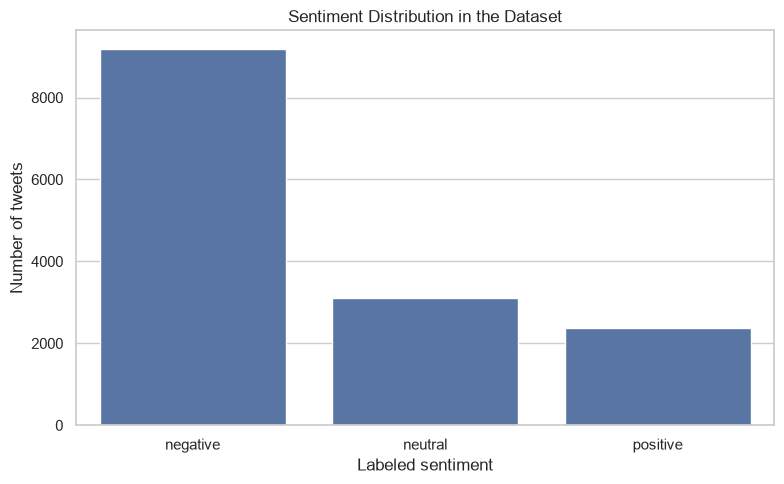

In [236]:
# I visualize the overall distribution of the supplied sentiment labels.
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="airline_sentiment",
    order=SENTIMENT_ORDER,
)
plt.title("Sentiment Distribution in the Dataset")
plt.xlabel("Labeled sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

airline_sentiment,negative,neutral,positive
airline,,,
American,71.04,16.78,12.18
Delta,42.98,32.54,24.48
Southwest,49.01,27.44,23.55
US Airways,77.69,13.08,9.23
United,68.89,18.24,12.87
Virgin America,35.91,33.93,30.16


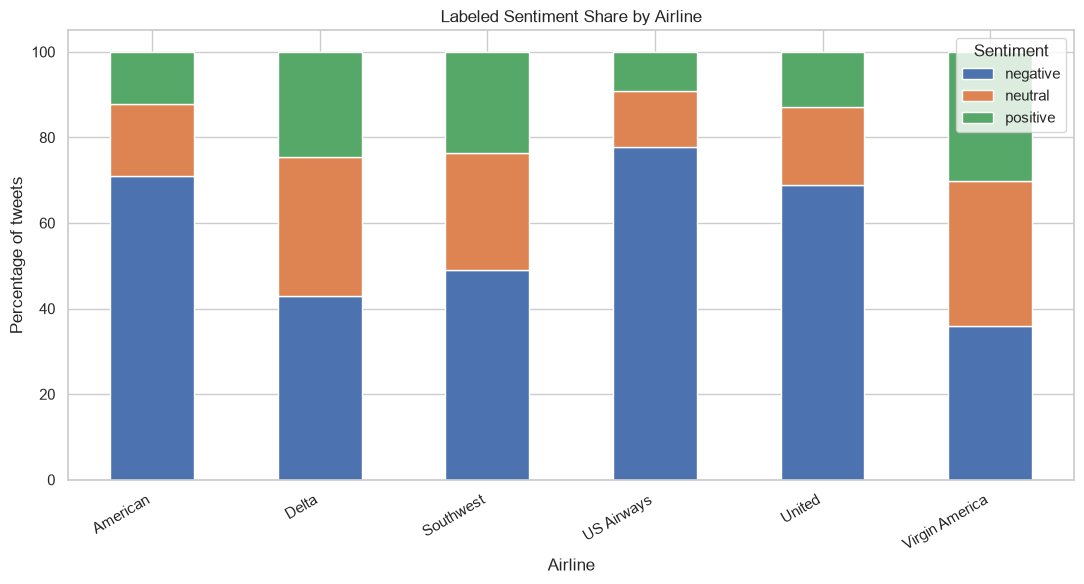

In [238]:
# I compare sentiment percentages within each airline, not raw tweet counts.
airline_counts = pd.crosstab(df["airline"], df["airline_sentiment"]).reindex(
    columns=SENTIMENT_ORDER, fill_value=0
)
airline_percentages = airline_counts.div(airline_counts.sum(axis=1), axis=0) * 100

show_table(airline_percentages.round(2))

airline_percentages.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.title("Labeled Sentiment Share by Airline")
plt.xlabel("Airline")
plt.ylabel("Percentage of tweets")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

Dataset date range (UTC):
2015-02-17 07:36:05+00:00 to 2015-02-24 19:53:37+00:00


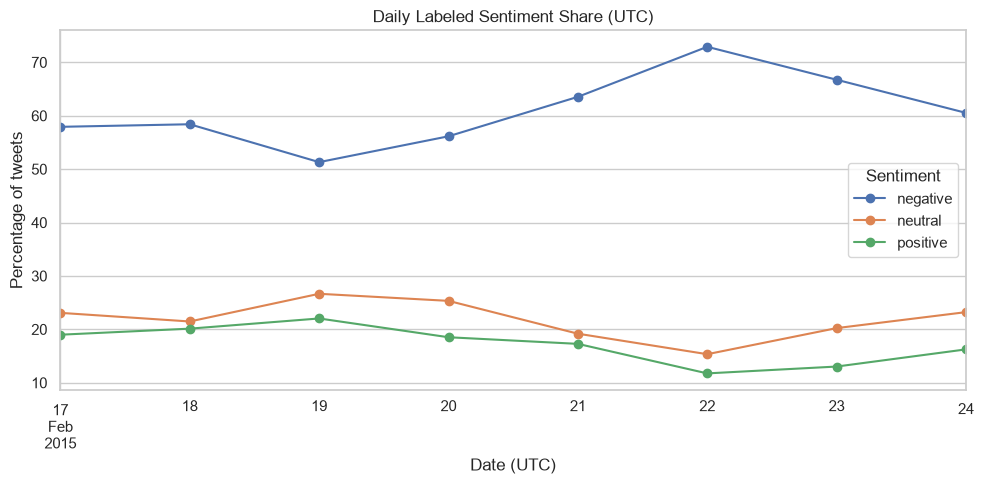

In [239]:
# I standardize timestamps to UTC before grouping tweets by date.
df["created_at_utc"] = pd.to_datetime(
    df["tweet_created"], errors="coerce", utc=True
)
df["tweet_date_utc"] = df["created_at_utc"].dt.floor("D")

print("Dataset date range (UTC):")
print(df["created_at_utc"].min(), "to", df["created_at_utc"].max())

daily_labeled_sentiment = pd.crosstab(
    df["tweet_date_utc"],
    df["airline_sentiment"],
    normalize="index",
).reindex(columns=SENTIMENT_ORDER, fill_value=0) * 100

daily_labeled_sentiment.plot(marker="o", figsize=(10, 5))
plt.title("Daily Labeled Sentiment Share (UTC)")
plt.xlabel("Date (UTC)")
plt.ylabel("Percentage of tweets")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

## 4. Preprocess the social-media text

In [241]:
# I define patterns that target the social-media noise required by the case study.
URL_PATTERN = r"https?://\S+|www\.\S+"
HASHTAG_PATTERN = r"#[\w]+"
MENTION_PATTERN = r"@[\w]+"
EMOTICON_PATTERN = (
    r"[<>]?[:;=8][\-o\*']?"
    r"[\)\]\(\[dDpP/:\}\{@\|\\]"
)
EMOJI_PATTERN = r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"

STOP_WORDS = set(stopwords.words("english"))
STOP_WORDS -= {"no", "not", "nor", "never"}

def remove_social_noise(text):
    """Remove URLs, hashtags, mentions, emoticons, and common emoji symbols."""
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(URL_PATTERN, " ", text, flags=re.IGNORECASE)
    text = re.sub(HASHTAG_PATTERN, " ", text)
    text = re.sub(MENTION_PATTERN, " ", text)
    text = re.sub(EMOTICON_PATTERN, " ", text)
    text = re.sub(EMOJI_PATTERN, " ", text)
    return re.sub(r"\s+", " ", text).strip()


def normalize_text(text):
    """Lowercase text, expand common contractions, and remove punctuation."""
    text = str(text).replace("’", "'").replace("‘", "'")

    # I expand frequent contractions before removing apostrophes.
    contractions = {
        r"\bwon't\b": "will not",
        r"\bcan't\b": "can not",
        r"\bshan't\b": "shall not",
        r"\blet's\b": "let us",
        r"\bi'm\b": "i am",
    }
    for pattern, replacement in contractions.items():
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)

    text = re.sub(r"\b(\w+)n't\b", r"\1 not", text, flags=re.IGNORECASE)
    text = re.sub(
        r"\b(i|you|we|they|could|would|should|might)'ve\b",
        r"\1 have", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"\b(i|you|we|they|who|what|there)'re\b",
        r"\1 are", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"\b(i|you|we|they|he|she|it)'ll\b",
        r"\1 will", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"\b(it|that|he|she|there|what|who)'s\b",
        r"\1 is", text, flags=re.IGNORECASE
    )

    text = text.lower()
    # I preserve digits because numbers can matter in complaints (for example, age limits).
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize_and_clean(normalized_text):
    """Tokenize normalized text and remove stop words without dropping negation."""
    tokens = word_tokenize(normalized_text)
    return [
        token for token in tokens
        if token.isalnum() and token not in STOP_WORDS
    ]


# I keep the intermediate columns so I can inspect each preprocessing stage.
df["noise_removed_text"] = df["text"].fillna("").apply(remove_social_noise)
df["normalized_text"] = df["noise_removed_text"].apply(normalize_text)
df["tokens"] = df["normalized_text"].apply(tokenize_and_clean)
df["clean_text"] = df["tokens"].apply(" ".join)

show_table(
    df[["text", "noise_removed_text", "normalized_text", "tokens", "clean_text"]]
    .head(8)
)

,text,noise_removed_text,normalized_text,tokens,clean_text
0,@VirginAmerica What @dhepburn said.,What said.,what said,[said],said
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,plus you have added commercials to the experie...,"[plus, added, commercials, experience, tacky]",plus added commercials experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,I didn't today... Must mean I need to take ano...,i did not today must mean i need to take anoth...,"[not, today, must, mean, need, take, another, ...",not today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,"it's really aggressive to blast obnoxious ""ent...",it is really aggressive to blast obnoxious ent...,"[really, aggressive, blast, obnoxious, enterta...",really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it,and it is a really big bad thing about it,"[really, big, bad, thing]",really big bad thing
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay $30 a flight for seats tha...,seriously would pay 30 a flight for seats that...,"[seriously, would, pay, 30, flight, seats, not...",seriously would pay 30 flight seats not playin...
6,"@VirginAmerica yes, nearly every time I fly VX...","yes, nearly every time I fly VX this âear wo...",yes nearly every time i fly vx this ear worm w...,"[yes, nearly, every, time, fly, vx, ear, worm,...",yes nearly every time fly vx ear worm go away
7,@VirginAmerica Really missed a prime opportuni...,Really missed a prime opportunity for Men With...,really missed a prime opportunity for men with...,"[really, missed, prime, opportunity, men, with...",really missed prime opportunity men without ha...


In [242]:
# I validate that targeted social-media noise is gone after the first cleaning stage.
noise_patterns = {
    "URLs": URL_PATTERN,
    "hashtags": HASHTAG_PATTERN,
    "mentions": MENTION_PATTERN,
    "emoticons": EMOTICON_PATTERN,
    "emoji symbols": EMOJI_PATTERN,
}

for label, pattern in noise_patterns.items():
    matches = df["noise_removed_text"].str.contains(
        pattern, regex=True, na=False
    ).sum()
    print(f"{label.capitalize()} remaining after noise removal: {matches}")

empty_after_stopwords = df["clean_text"].str.strip().eq("")
empty_after_normalization = df["normalized_text"].str.strip().eq("")

print(f"\nTweets empty after stop-word removal: {empty_after_stopwords.sum():,}")
print(f"Tweets empty before stop-word removal: {empty_after_normalization.sum():,}")
print(
    "Average words before stop-word removal:",
    round(df["normalized_text"].str.split().str.len().mean(), 2)
)
print(
    "Average words after stop-word removal:",
    round(df["clean_text"].str.split().str.len().mean(), 2)
)

Urls remaining after noise removal: 0
Hashtags remaining after noise removal: 0
Mentions remaining after noise removal: 0
Emoticons remaining after noise removal: 0
Emoji symbols remaining after noise removal: 0

Tweets empty after stop-word removal: 23
Tweets empty before stop-word removal: 0
Average words before stop-word removal: 16.6
Average words after stop-word removal: 9.19


## 5. Create a held-out test set

I preserve all three classes and remove only tweets that have no text after URL/social-noise removal and normalization. I split the data before tuning. The held-out test set is reserved for final evaluation; the search will use cross-validation on the training set only.

The training target is airline_sentiment. I do not use negativereason, airline name, or timestamp as model features, because this part of the project predicts sentiment from the text.

In [244]:
model_data = df.loc[
    df["normalized_text"].str.strip().ne(""),
    ["text", "airline", "airline_sentiment", "created_at_utc",
     "tweet_date_utc", "normalized_text", "clean_text"],
].copy()

X = model_data["text"].astype(str)  # I pass raw text through the same cleaner inside the pipeline.
y = model_data["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Rows available for modeling: {len(model_data):,}")
print(f"Training rows: {len(X_train):,}")
print(f"Held-out test rows: {len(X_test):,}")
print("\nTraining labels:")
show_table(y_train.value_counts().reindex(SENTIMENT_ORDER).rename("count").to_frame())
print("\nTest labels:")
show_table(y_test.value_counts().reindex(SENTIMENT_ORDER).rename("count").to_frame())

Rows available for modeling: 14,640
Training rows: 11,712
Held-out test rows: 2,928

Training labels:


,count
airline_sentiment,
negative,7343
neutral,2479
positive,1890



Test labels:


,count
airline_sentiment,
negative,1835
neutral,620
positive,473


## 6. Build a preprocessing-and-model pipeline

I put text cleaning inside a scikit-learn transformer so every model uses the same preprocessing at prediction time. I also let the search compare keeping stop words against removing them rather than assuming one approach is best.

For model selection, I search a defined set of word/character TF-IDF settings and linear SVM configurations. The search maximizes cross-validated accuracy, as requested, and also records macro F1 so I can see whether performance is being sacrificed on minority classes. This finds the best configuration among the candidates I test; it cannot guarantee the global optimum.

In [245]:
class TweetTextCleaner(BaseEstimator, TransformerMixin):
    """I make the case-study text cleaning reusable inside an sklearn pipeline."""

    def __init__(self, remove_stopwords=False):
        self.remove_stopwords = remove_stopwords

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        cleaned = []
        for raw_text in X:
            text = normalize_text(remove_social_noise(raw_text))
            if self.remove_stopwords:
                text = " ".join(tokenize_and_clean(text))
            cleaned.append(text)
        return cleaned


# I set up a simple baseline using the strongest fixed configuration from my earlier tests.
baseline_model = Pipeline([
    ("cleaner", TweetTextCleaner(remove_stopwords=True)),
    ("tfidf", TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
    )),
    ("classifier", SVC(kernel="linear", C=1.0)),
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_macro_f1 = f1_score(y_test, baseline_predictions, average="macro")

print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Baseline test macro F1: {baseline_macro_f1:.4f}")

Baseline test accuracy: 0.7903
Baseline test macro F1: 0.7170


## 7. Tune the model using training data only

I use three-fold stratified cross-validation and randomized search to explore:
- retaining or removing stop words;
- word unigrams/bigrams/trigrams and character n-grams;
- minimum document frequency and TF-IDF scaling;
- SVC versus LinearSVC;
- regularization strength (C) and optional class weighting.

I select the best configuration by mean cross-validated accuracy. The test set is not passed to RandomizedSearchCV, so tuning does not directly optimize against the held-out test answers. The search may take a few minutes; increase N_ITER for a broader search if runtime allows.

In [246]:
from sklearn.model_selection import RandomizedSearchCV

pipeline_for_search = Pipeline([
    ("cleaner", TweetTextCleaner()),
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC(random_state=RANDOM_STATE)),
])

# I search both word features and character features; character n-grams can capture
# short, informal, or misspelled expressions common in social posts.
parameter_spaces = [
    {
        "cleaner__remove_stopwords": [False, True],
        "tfidf__analyzer": ["word"],
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "tfidf__min_df": [1, 2, 3],
        "tfidf__max_df": [0.95, 1.0],
        "tfidf__sublinear_tf": [False, True],
        "classifier": [
            LinearSVC(random_state=RANDOM_STATE),
            SVC(kernel="linear"),
        ],
        "classifier__C": [0.5, 1.0, 2.0, 4.0],
        "classifier__class_weight": [None, "balanced"],
    },
    {
        "cleaner__remove_stopwords": [False],
        "tfidf__analyzer": ["char"],
        "tfidf__ngram_range": [(2, 5), (3, 5)],
        "tfidf__min_df": [2, 3, 5],
        "tfidf__max_df": [1.0],
        "tfidf__sublinear_tf": [False, True],
        "classifier": [LinearSVC(random_state=RANDOM_STATE)],
        "classifier__C": [0.5, 1.0, 2.0, 4.0],
        "classifier__class_weight": [None, "balanced"],
    },
]

CV = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# I keep the first search manageable while exploring several model families.
N_ITER = 40

search = RandomizedSearchCV(
    estimator=pipeline_for_search,
    param_distributions=parameter_spaces,
    n_iter=N_ITER,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
    },
    refit="accuracy",
    cv=CV,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    pre_dispatch="n_jobs",
    verbose=1,
    return_train_score=False,
)

search.fit(X_train, y_train)

print(f"Best mean CV accuracy: {search.best_score_:.4f}")
print("\nBest parameters:")
for parameter, value in search.best_params_.items():
    print(f"{parameter}: {value}")

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Best mean CV accuracy: 0.7957

Best parameters:
tfidf__sublinear_tf: True
tfidf__ngram_range: (3, 5)
tfidf__min_df: 3
tfidf__max_df: 1.0
tfidf__analyzer: char
cleaner__remove_stopwords: False
classifier__class_weight: None
classifier__C: 1.0
classifier: LinearSVC(random_state=42)


In [247]:
# I review the highest-scoring configurations rather than trusting a single number.
cv_results = pd.DataFrame(search.cv_results_)
top_configurations = cv_results.sort_values(
    "mean_test_accuracy", ascending=False
)[[
    "mean_test_accuracy",
    "mean_test_macro_f1",
    "std_test_accuracy",
    "params",
]].head(10)

show_table(top_configurations.reset_index(drop=True).round(4))

,mean_test_accuracy,mean_test_macro_f1,std_test_accuracy,params
0,0.7957,0.7261,0.0033,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
1,0.7954,0.7230,0.0048,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
2,0.7951,0.7321,0.0035,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
3,0.7918,0.7230,0.0035,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
4,0.7918,0.7085,0.0045,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
5,0.7905,0.7266,0.0037,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
6,0.7899,0.7253,0.0041,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
7,0.7884,0.7205,0.0024,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
8,0.7847,0.7143,0.0033,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
9,0.7844,0.6940,0.0022,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."


## 8. Evaluate once on the held-out test set

I now evaluate the selected model on the test set that was not used during tuning. Accuracy gives the overall proportion classified correctly; macro F1 treats the three classes equally. I also inspect per-class precision and recall because the dataset is imbalanced.

In [248]:
best_model = search.best_estimator_
tuned_predictions = best_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, tuned_predictions)
tuned_macro_f1 = f1_score(y_test, tuned_predictions, average="macro")
tuned_weighted_f1 = f1_score(y_test, tuned_predictions, average="weighted")

print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Tuned test accuracy:    {tuned_accuracy:.4f}")
print(f"Tuned macro F1:         {tuned_macro_f1:.4f}")
print(f"Tuned weighted F1:      {tuned_weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    tuned_predictions,
    labels=SENTIMENT_ORDER,
    zero_division=0,
))

Baseline test accuracy: 0.7903
Tuned test accuracy:    0.7917
Tuned macro F1:         0.7200
Tuned weighted F1:      0.7857

Classification report:
              precision    recall  f1-score   support

    negative       0.84      0.91      0.87      1835
     neutral       0.65      0.58      0.61       620
    positive       0.76      0.60      0.67       473

    accuracy                           0.79      2928
   macro avg       0.75      0.70      0.72      2928
weighted avg       0.79      0.79      0.79      2928



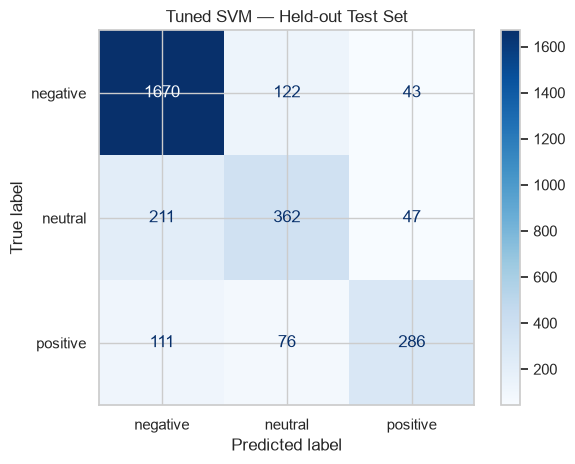

In [249]:
# I use a confusion matrix to see which sentiment pairs are most often confused.
cm = confusion_matrix(y_test, tuned_predictions, labels=SENTIMENT_ORDER)
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=SENTIMENT_ORDER,
)
cm_display.plot(values_format="d", cmap="Blues")
plt.title("Tuned SVM — Held-out Test Set")
plt.tight_layout()
plt.show()

In [250]:
# I inspect errors to understand what the model still gets wrong.
test_errors = pd.DataFrame({
    "text": X_test.to_numpy(),
    "actual_sentiment": y_test.to_numpy(),
    "predicted_sentiment": tuned_predictions,
})
test_errors = test_errors[
    test_errors["actual_sentiment"] != test_errors["predicted_sentiment"]
].copy()

print(f"Misclassified test tweets: {len(test_errors):,} of {len(y_test):,}")
print("\nErrors where the true label is neutral:")
show_table(
    test_errors.loc[
        test_errors["actual_sentiment"].eq("neutral"),
        ["text", "actual_sentiment", "predicted_sentiment"],
    ].head(10)
)

Misclassified test tweets: 610 of 2,928

Errors where the true label is neutral:


,text,actual_sentiment,predicted_sentiment
0,@united past,neutral,negative
6,@united This link in your tweet goes to someon...,neutral,negative
30,"@southwestair *any site*? gmail, facebook, etc.",neutral,negative
33,@JetBlue such a bummer. But I understand it's...,neutral,negative
48,@SouthwestAir @MegElizabeth631 how you like th...,neutral,negative
55,@SouthwestAir I was under the impression when ...,neutral,negative
64,"@AmericanAir @derekc21 , so what would be a fi...",neutral,negative
70,@SouthwestAir have five people shown up yet,neutral,negative
117,@AmericanAir @RobertDwyer AA doesnt charge any...,neutral,positive
118,@united Want to book a multi-city fare. Have m...,neutral,negative


## 9. Prepare the model for new posts

After final test evaluation, I refit the selected configuration on all available labeled text so the monitoring function can use as much labeled data as possible. I keep the held-out test metrics above as the honest estimate of generalization; I do not report training-set performance as test accuracy.

In [251]:
production_model = clone(search.best_estimator_)
production_model.fit(X, y)

print("Production model refit on all labeled tweets.")
print("Classes:", production_model.named_steps["classifier"].classes_)

Production model refit on all labeled tweets.
Classes: ['negative' 'neutral' 'positive']


## 10. Predict sentiment for individual posts
I pass raw posts to the trained pipeline, which applies the selected cleaning strategy and model in the same order used during training. If a post contains no text after cleaning, I return `insufficient text` instead of forcing a prediction.

In [253]:
def prepare_tweet_for_review(text, remove_stopwords):
    # I use this only to check whether any meaningful text survives cleaning.
    text = normalize_text(remove_social_noise(text))
    if remove_stopwords:
        text = " ".join(tokenize_and_clean(text))
    return text


def predict_tweet_sentiment(text):
    use_stopwords = production_model.named_steps["cleaner"].remove_stopwords
    cleaned_text = prepare_tweet_for_review(text, use_stopwords)

    if not cleaned_text.strip():
        return {
            "clean_text": cleaned_text,
            "predicted_sentiment": "insufficient text",
        }

    predicted = production_model.predict([text])[0]
    return {
        "clean_text": cleaned_text,
        "predicted_sentiment": predicted,
    }


# I test the pipeline with illustrative posts containing social-media noise.
sample_posts = [
    "@VirginAmerica The service was fantastic! Thank you :) #great",
    "@United My flight was delayed for hours. Terrible service! https://example.com",
    "@Delta The flight was okay, nothing special.",
    "@AirlineX I can't recommend this airline after they lost my bag.",
    "@AirlineX #travel https://example.com",
]

sample_predictions = []
for post in sample_posts:
    result = predict_tweet_sentiment(post)
    sample_predictions.append({
        "original_text": post,
        "clean_text": result["clean_text"],
        "predicted_sentiment": result["predicted_sentiment"],
    })

show_table(pd.DataFrame(sample_predictions))

,original_text,clean_text,predicted_sentiment
0,@VirginAmerica The service was fantastic! Than...,the service was fantastic thank you,positive
1,@United My flight was delayed for hours. Terri...,my flight was delayed for hours terrible service,negative
2,"@Delta The flight was okay, nothing special.",the flight was okay nothing special,negative
3,@AirlineX I can't recommend this airline after...,i can not recommend this airline after they lo...,negative
4,@AirlineX #travel https://example.com,,insufficient text


## 11. Historical brand-reputation report
I summarize the dataset's original labels by airline. This shows the historical sentiment distribution in the supplied data and is distinct from the model's predictions for new posts.

airline_sentiment,negative,neutral,positive,tweet_count,negative_pct,neutral_pct,positive_pct,net_sentiment
airline,,,,,,,,
US Airways,2263,381,269,2913,77.69,13.08,9.23,-68.45
American,1960,463,336,2759,71.04,16.78,12.18,-58.86
United,2633,697,492,3822,68.89,18.24,12.87,-56.02
Southwest,1186,664,570,2420,49.01,27.44,23.55,-25.45
Delta,955,723,544,2222,42.98,32.54,24.48,-18.50
Virgin America,181,171,152,504,35.91,33.93,30.16,-5.75


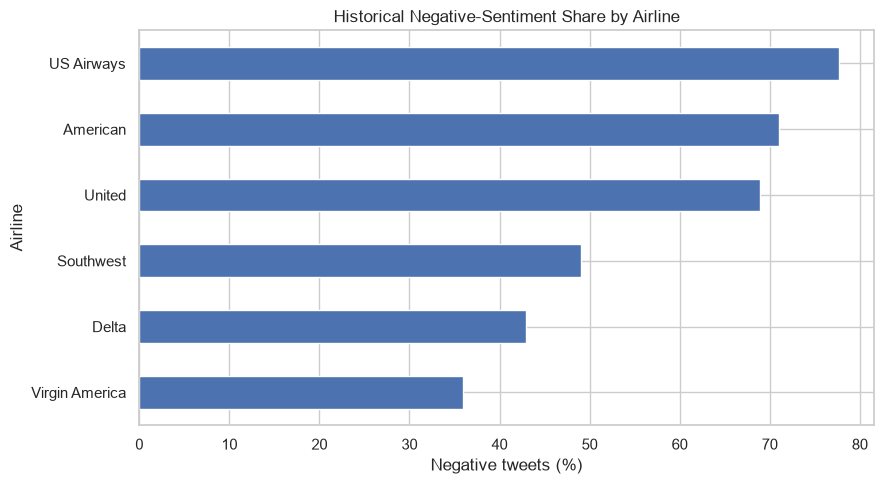

In [255]:
historical_brand_report = pd.crosstab(
    df["airline"],
    df["airline_sentiment"],
).reindex(columns=SENTIMENT_ORDER, fill_value=0)

historical_brand_report["tweet_count"] = historical_brand_report.sum(axis=1)

for sentiment in SENTIMENT_ORDER:
    historical_brand_report[f"{sentiment}_pct"] = (
        historical_brand_report[sentiment]
        / historical_brand_report["tweet_count"] * 100
    )

historical_brand_report["net_sentiment"] = (
    historical_brand_report["positive_pct"]
    - historical_brand_report["negative_pct"]
)

historical_brand_report = historical_brand_report.sort_values(
    "negative_pct", ascending=False
)

show_table(historical_brand_report.round(2))

historical_brand_report["negative_pct"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Historical Negative-Sentiment Share by Airline")
plt.xlabel("Negative tweets (%)")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

## 12. Monitor incoming posts by brand and date
I define a monitoring function for a new batch of posts. The input needs three fields: `brand`, `created_at`, and `text`. The function predicts sentiment, aggregates the predictions by brand and UTC date, and flags periods for review only when both the negative percentage and the minimum volume threshold are met.

The thresholds below are starting examples, not validated business rules. In a real monitoring system, I would choose them using historical baselines and alert-volume requirements.

In [257]:
def monitor_posts(posts, negative_threshold=60, min_posts=20):
    required_columns = {"brand", "created_at", "text"}
    missing = required_columns - set(posts.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    results = posts.copy()
    results["created_at"] = pd.to_datetime(
        results["created_at"], errors="coerce", utc=True
    )

    predictions = results["text"].fillna("").apply(predict_tweet_sentiment)
    results["clean_text"] = predictions.apply(lambda item: item["clean_text"])
    results["predicted_sentiment"] = predictions.apply(
        lambda item: item["predicted_sentiment"]
    )
    results["monitor_date_utc"] = results["created_at"].dt.floor("D")

    analyzable = results[
        results["predicted_sentiment"].isin(SENTIMENT_ORDER)
        & results["monitor_date_utc"].notna()
        & results["brand"].notna()
    ].copy()

    if analyzable.empty:
        return results, pd.DataFrame()

    counts = pd.crosstab(
        [analyzable["brand"], analyzable["monitor_date_utc"]],
        analyzable["predicted_sentiment"],
    ).reindex(columns=SENTIMENT_ORDER, fill_value=0)

    report = counts.copy()
    report["post_count"] = counts.sum(axis=1)

    for sentiment in SENTIMENT_ORDER:
        report[f"{sentiment}_pct"] = (
            counts[sentiment] / report["post_count"] * 100
        )

    report = report.reset_index()
    alert = (
        (report["post_count"] >= min_posts)
        & (report["negative_pct"] >= negative_threshold)
    )
    report["status"] = "Monitor"
    report.loc[alert, "status"] = "Review negative sentiment"

    return results, report


# I use clearly illustrative posts to test the monitoring function end to end.
incoming_posts = pd.DataFrame([
    {
        "brand": "United",
        "created_at": "2025-02-24 09:00:00",
        "text": "@United My flight was delayed again. Terrible service!",
    },
    {
        "brand": "United",
        "created_at": "2025-02-24 10:00:00",
        "text": "@United The staff were helpful and friendly. Thank you!",
    },
    {
        "brand": "Delta",
        "created_at": "2025-02-24 10:30:00",
        "text": "@Delta The flight was comfortable and the crew was great!",
    },
    {
        "brand": "Delta",
        "created_at": "2025-02-24 11:00:00",
        "text": "@Delta My luggage is missing. This is unacceptable.",
    },
    {
        "brand": "Southwest",
        "created_at": "2025-02-25 08:00:00",
        "text": "@Southwest Boarding was smooth and the staff were wonderful!",
    },
    {
        "brand": "Southwest",
        "created_at": "2025-02-25 09:00:00",
        "text": "@Southwest My flight was cancelled and nobody helped me.",
    },
])

monitored_posts, daily_brand_report = monitor_posts(incoming_posts)

print("Post-level predictions:")
show_table(
    monitored_posts[
        ["brand", "created_at", "text", "clean_text", "predicted_sentiment"]
    ]
)

print("\nBrand/date report:")
show_table(daily_brand_report.round(2))

Post-level predictions:


,brand,created_at,text,clean_text,predicted_sentiment
0,United,2025-02-24 09:00:00+00:00,@United My flight was delayed again. Terrible ...,my flight was delayed again terrible service,negative
1,United,2025-02-24 10:00:00+00:00,@United The staff were helpful and friendly. T...,the staff were helpful and friendly thank you,positive
2,Delta,2025-02-24 10:30:00+00:00,@Delta The flight was comfortable and the crew...,the flight was comfortable and the crew was great,positive
3,Delta,2025-02-24 11:00:00+00:00,@Delta My luggage is missing. This is unaccept...,my luggage is missing this is unacceptable,negative
4,Southwest,2025-02-25 08:00:00+00:00,@Southwest Boarding was smooth and the staff w...,boarding was smooth and the staff were wonderful,positive
5,Southwest,2025-02-25 09:00:00+00:00,@Southwest My flight was cancelled and nobody ...,my flight was cancelled and nobody helped me,negative



Brand/date report:


/var/folders/1_/cwllcfjj5l5f3xkph9p87b7w0000gn/T/ipykernel_48445/2355620476.py:96: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  show_table(daily_brand_report.round(2))


predicted_sentiment,brand,monitor_date_utc,negative,neutral,positive,post_count,negative_pct,neutral_pct,positive_pct,status
0,Delta,2025-02-24 00:00:00+00:00,1,0,1,2,50.0,0.0,50.0,Monitor
1,Southwest,2025-02-25 00:00:00+00:00,1,0,1,2,50.0,0.0,50.0,Monitor
2,United,2025-02-24 00:00:00+00:00,1,0,1,2,50.0,0.0,50.0,Monitor


## Conclusion

I built a full workflow for social-media sentiment monitoring: cleaning and validating posts, tuning a three-class SVM pipeline, evaluating it on held-out data, scoring new posts, and summarizing results by brand and date.

I report both accuracy and macro F1 because the dataset is imbalanced. The tuned result and class-level metrics printed during execution—not a prefilled number—are the results I should use in my conclusion. The 2015 dataset is suitable for this case study, but it is not evidence of current airline reputation.